# Praktikum Data Mining – Evaluasi Model Klasifikasi
## Tugas 1 – Hitung Manual

Kelompok 7 Data Mining

Anggota: Lutfiah Sahira (24343039), Imam Atthahira (24343037) , Rangga Dharma Putra (24343045). Mata kuliah: Data Mining· Dosen pengampu: Dr. Yeka Hendriyani, S.Kom., M.Kom. Program Studi Informatika, Departemen Teknik Elektronika, Fakultas Teknik, Universitas Negeri Padang


### Persiapan (data, model, dan prediksi dari langkah sebelumnya)

In [1]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)
df = pd.DataFrame({'amount':amount.round(2), 'hour':hour,
                   'new_device':new_device, 'foreign_ip':foreign_ip,
                   'isFraud':isFraud})

import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, classification_report)

### Sel T1

Confusion matrix (baris=aktual, kolom=prediksi):
 [[156  12]
 [  8  24]]
Accuracy  = (24+156)/200 = 0.9000
Precision = 24/(24+12) = 0.6667
Recall    = 24/(24+8) = 0.7500
F1-score  = 0.7059


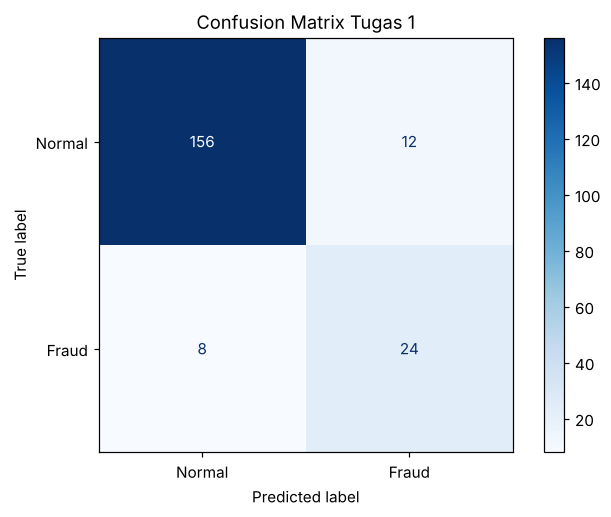

In [2]:
tp1, tn1, fp1, fn1 = 24, 156, 12, 8
cm1 = np.array([[tn1, fp1], [fn1, tp1]])
print('Confusion matrix (baris=aktual, kolom=prediksi):\n', cm1)
acc1 = (tp1 + tn1) / (tp1 + tn1 + fp1 + fn1)
pre1 = tp1 / (tp1 + fp1)
rec1 = tp1 / (tp1 + fn1)
f11 = 2 * pre1 * rec1 / (pre1 + rec1)
print(f'Accuracy  = ({tp1}+{tn1})/{tp1+tn1+fp1+fn1} = {acc1:.4f}')
print(f'Precision = {tp1}/({tp1}+{fp1}) = {pre1:.4f}')
print(f'Recall    = {tp1}/({tp1}+{fn1}) = {rec1:.4f}')
print(f'F1-score  = {f11:.4f}')
ConfusionMatrixDisplay(cm1, display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix Tugas 1'); plt.tight_layout()
plt.savefig('fig_task1_cm.png', dpi=150); plt.show()